# Falling drop

A drop of Lennard-Jones particles falls into a pool, pulled down by a constant force. This is the `fallingDrop.yaml` scenario of md-flexible, set up in two ways which lead to the same simulation:

1. [configured in place](#1.-Configured-in-place) with a dictionary,
2. [from the YAML file](#2.-From-the-YAML-file) md-flexible uses.

Each run takes one to two minutes on a laptop. To run this notebook, install the module with `pip install ".[plot]"` and `jupyterlab` into your environment.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

import autopas as ap
from autopas.plotting import animate_particles, plot_particles


def run_as_gif(sim, path, *, frames=70, iterations_per_frame=100):
    """Advances the simulation by frames * iterations_per_frame iterations, and shows it as a GIF."""
    animation = animate_particles(
        sim,
        frames=frames,
        iterations_per_frame=iterations_per_frame,
        color_by="speed",
        speed_max=20.0,  # A fixed scale, so that a color means the same speed in every frame
        size=1.0,
    )
    animation.save(path, writer="pillow", fps=12, dpi=80)
    plt.close("all")
    return Image(filename=path)

## 1. Configured in place

The configuration is a dictionary with the same keys as the YAML files. Only `Objects` is written differently here: Here, it takes generators from `ap.generators` instead of the nested section of a YAML file.

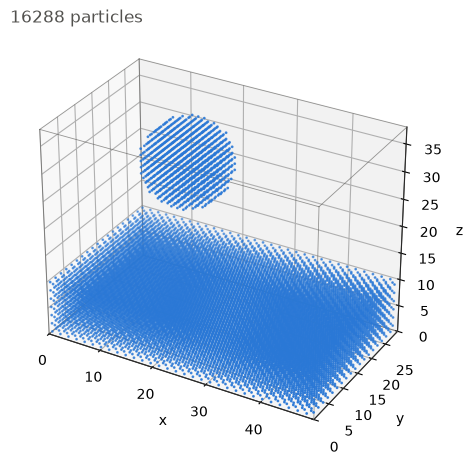

In [2]:
PARTICLE_SPACING = 1.122462048  # 2^(1/6), the distance with the lowest potential energy

config = {
    # The simulated system
    "box-min": [0.0, 0.0, 0.0],
    "box-max": [49.5, 29.5, 38.0],
    "boundary-type": ["reflective", "reflective", "reflective"],
    "cutoff": 3.0,
    "deltaT": 0.0005,
    "globalForce": [0.0, 0.0, -12.0],
    "Sites": {0: {"epsilon": 1.0, "sigma": 1.0, "mass": 1.0}},
    "Objects": [
        # The pool
        ap.generators.CubeClosestPacked(
            [49.5, 29.5, 10.0], particle_spacing=PARTICLE_SPACING, structure="fcc", centered=True
        ),
        # The drop
        ap.generators.Sphere([18.0, 15.0, 30.0], 6, particle_spacing=PARTICLE_SPACING),
    ],
    # What AutoPas may choose from while tuning
    "container": ["LinkedCells", "VerletLists", "VerletListsCells", "VerletClusterLists"],
    "traversal": [
        "lc_c01", "lc_c18", "lc_c08", "lc_sliced_c02",
        "vl_list_iteration",
        "vlc_c01", "vlc_c18", "vlc_sliced_c02",
        "vcl_cluster_iteration", "vcl_c01_balanced", "vcl_c06",
    ],
    "data-layout": ["AoS", "SoA"],
    "newton3": ["disabled", "enabled"],
    "selector-strategy": "Fastest-Absolute-Value",
    "tuning-interval": 2500,
    "tuning-samples": 3,
    "verlet-rebuild-frequency": 10,
    "verlet-skin-radius": 1.0,
    "verlet-cluster-size": 4,
    "log-level": "warn",
}

ap_instance = ap.AutoPas(config, functors=ap.LennardJones())
plot_particles(ap_instance, size=1.0, title=f"{ap_instance.num_particles} particles")
plt.show()

Calling the object runs the simulation. `animate_particles` does that frame by frame, 7000 iterations in total. The drop hits the pool after about 3000 iterations.

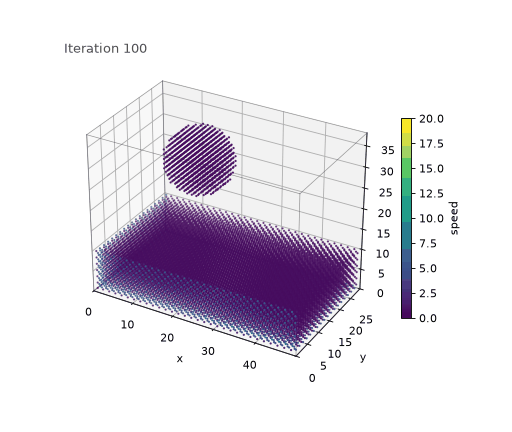

In [3]:
run_as_gif(ap_instance, "fallingDrop_inPlace.gif")

The simulation stays usable afterwards: Another call resumes from the current state.

In [4]:
ap_instance(100)
ap_instance.iteration, ap_instance.current_configuration

(7100,
 {'pairwise': '{Interaction Type: pairwise , Container: VerletLists , CellSizeFactor: 1.000000 , Traversal: vl_list_iteration , Load Estimator: none , Data Layout: SoA , Newton 3: disabled , VectorizationPattern: 1xVectorLength}'})

## 2. From the YAML file

The path to a YAML file is an equally valid constructor argument. Everything comes from the file, including the functor, which is `lj-hwy` here.

Two things follow from what the file asks for:

- **VTK output.** Every 100 iterations it writes about 2 MB to `vtkOutputFolder/` next to this notebook, which you can open in ParaView. Git ignores these files, delete them whenever you like.
- **A warning about energies.** `LennardJonesHWY` currently miscounts the potential energy and virial with SoA when halo particles are involved. Forces are correct, so this does not change the trajectories shown here.

In [5]:
ap_instance_yaml = ap.AutoPas("../examples/md-flexible/input/fallingDrop.yaml")

np.array_equal(ap.AutoPas(config, functors=ap.LennardJones()).positions, ap_instance_yaml.positions)

/var/folders/d7/j4pv5c3d1nj5jmjlz_bpj2lh0000gn/T/ipykernel_71342/1822542947.py:1: UserWarning: LennardJonesHWY reports a wrong potential energy and virial for the SoA data layout if there are halo particles. Forces are correct. Use LennardJones or restrict data-layout to AoS if you need the energies.
  from_yaml = ap.AutoPas("../examples/md-flexible/input/fallingDrop.yaml")


True

Both ways start from exactly the same particles. The run looks the same as well, though not down to the last particle: The two functors differ by rounding errors, which grow quickly in a chaotic system.

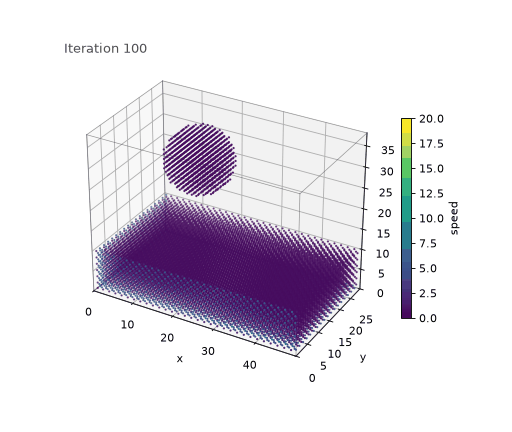

In [6]:
run_as_gif(ap_instance_yaml, "fallingDrop_fromYaml.gif")